<center>
  <h1>Aritméticas Fuzzy via $\mathcal{J}_gamma$</h1>
  <h3>Uma implementação computacional da soma e subtração fuzzy interativas</h3>
  <b>Yasmin B. Shimizu</b>
</center>

---


<p style="text-align: center">
  Este notebook contém testes de um <i>script</i> para operaões aritméticas fuzzy interativas, envolvendo as somas e subtrações fuzzy interativas, e comparações com generalizações da operação de subtração.
</p>

<p style="text-align: center;">
  Parte do Projeto de Iniciação Científica <b>Estudo de interatividade e aritmética fuzzy com aplicações em quadrados mínimos fuzzy e problemas inversos</b> (FAPESP n° 2025/26138-6).
</p>


<center>
  <img src="https://github.com/yasminbshimizu/IC_Fuzzy_Aritmetica_Interatividade_QuadradosMinimosPI/blob/main/Images/logo_fapesp_ilum_sfundo.png?raw=true" width="1000"/>
</center>

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Distribuições de Possibilidade Conjunta

In [2]:
def fill_ntrifuzzy_3D(ax, p1, p2, p3):

    n = 100

    # Parâmetros
    u = np.linspace(0, 1, n)
    v = np.linspace(0, 1, n)

    U, V = np.meshgrid(u, v)

    # Coordenadas dos vértices
    x1, y1, z1 = p1
    x2, y2, z2 = p2
    x3, y3, z3 = p3

    # Coordenadas baricêntricas
    W = 1 - U - V

    # Mantém somente a região triangular
    mask = W < 0

    X = W * x1 + U * x2 + V * x3
    Y = W * y1 + U * y2 + V * y3
    Z = W * z1 + U * z2 + V * z3

    X[mask] = np.nan
    Y[mask] = np.nan
    Z[mask] = np.nan

    ax.plot_surface(
        X,
        Y,
        Z,
        color="green",
        alpha=0.2,
        linewidth=0,
        antialiased=True
    )

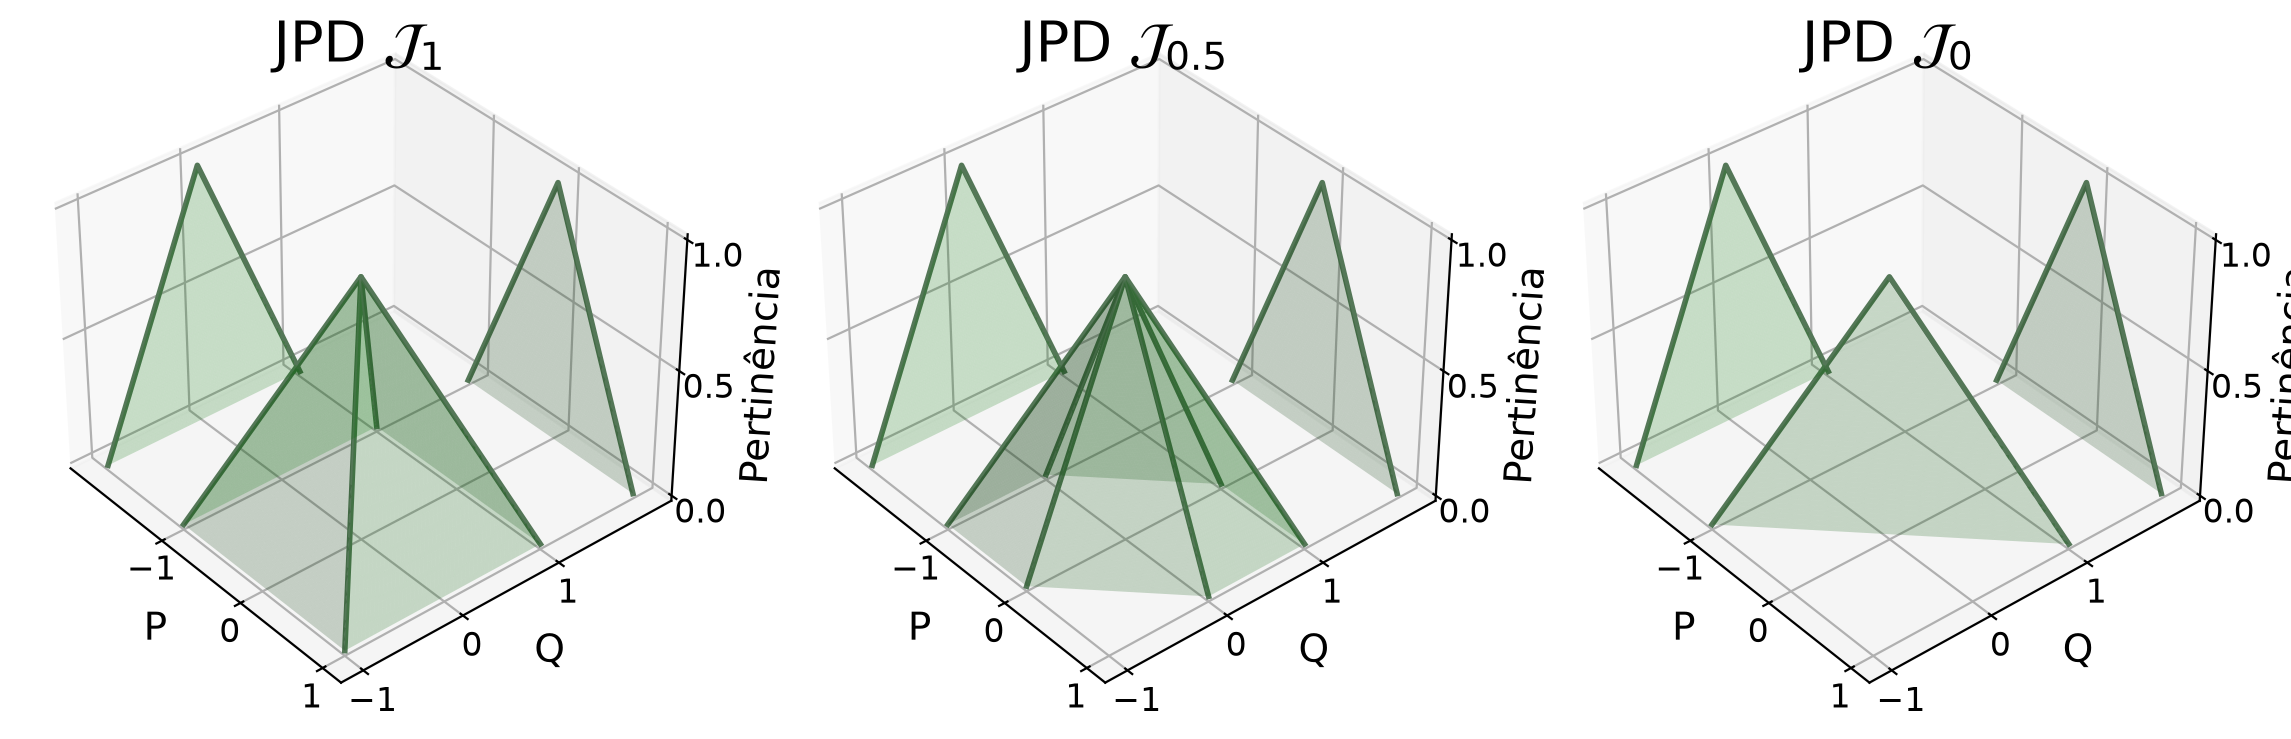

In [3]:
A = np.array([-1, 0, 1])
muA = np.array([0, 1, 0])

fig = plt.figure(figsize=(13, 4), dpi=200)

# JPD Gamma 1
ax1 = fig.add_subplot(131, projection='3d')

ax1.plot(A, [2,2,2], muA, color="#547757", linewidth=2)
ax1.plot([-2,-2,-2], A, muA, color="#547757", linewidth=2)

fill_ntrifuzzy_3D(ax1, [-1,2,0], [0,2,1], [1,2,0])
fill_ntrifuzzy_3D(ax1, [-2,-1,0], [-2,0,1], [-2,1,0])

ax1.plot(A, A, muA, color="#547757", linewidth=2)
ax1.plot(A, -A, muA, color="#547757", linewidth=2)

pico = [0,0,1]
fill_ntrifuzzy_3D(ax1, [-1,-1,0], pico, [1,-1,0])
fill_ntrifuzzy_3D(ax1, [1,-1,0], pico, [1,1,0])
fill_ntrifuzzy_3D(ax1, [-1,1,0], pico, [1,1,0])
fill_ntrifuzzy_3D(ax1, [-1,-1,0], pico, [-1,1,0])

ax1.set_title(r"JPD $\mathcal{J}_1$", y=1, fontsize=20)
ax1.set_xlabel("P", labelpad=-4, fontsize=14)
ax1.set_ylabel("Q", labelpad=-4, fontsize=14)
ax1.set_zlabel("Pertinência", labelpad=-4, fontsize=14)

# JPD Gamma 0.5
ax2 = fig.add_subplot(132, projection='3d')

ax2.plot(A, [2,2,2], muA, color="#547757", linewidth=2)
ax2.plot([-2,-2,-2], A, muA, color="#547757", linewidth=2)

fill_ntrifuzzy_3D(ax2, [-1,2,0], [0,2,1], [1,2,0])
fill_ntrifuzzy_3D(ax2, [-2,-1,0], [-2,0,1], [-2,1,0])

ax2.plot(A, A, muA, color="#547757", linewidth=2)
ax2.plot(A, [0,0,0], muA, color="#547757", linewidth=2)
ax2.plot([0,0,0], A, muA, color="#547757", linewidth=2)

pico = [0,0,1]
fill_ntrifuzzy_3D(ax2, [-1,0,0], pico, [-1,-1,0])
fill_ntrifuzzy_3D(ax2, [-1,-1,0], pico, [0,-1,0])
fill_ntrifuzzy_3D(ax2, [0,-1,0], pico, [1,0,0])
fill_ntrifuzzy_3D(ax2, [1,0,0], pico, [1,1,0])
fill_ntrifuzzy_3D(ax2, [1,1,0], pico, [0,1,0])
fill_ntrifuzzy_3D(ax2, [0,1,0], pico, [-1,0,0])

ax2.set_title(r"JPD $\mathcal{J}_{0.5}$", y=1, fontsize=20)
ax2.set_xlabel("P", labelpad=-4, fontsize=14)
ax2.set_ylabel("Q", labelpad=-4, fontsize=14)
ax2.set_zlabel("Pertinência", labelpad=-4, fontsize=14)

# JPD Gamma 0
ax3 = fig.add_subplot(133, projection='3d')

ax3.plot(A, [2,2,2], muA, color="#547757", linewidth=2)
ax3.plot([-2,-2,-2], A, muA, color="#547757", linewidth=2)

fill_ntrifuzzy_3D(ax3, [-1,2,0], [0,2,1], [1,2,0])
fill_ntrifuzzy_3D(ax3, [-2,-1,0], [-2,0,1], [-2,1,0])

ax3.plot(A, A, muA, color="#547757", linewidth=2)

pico = [0,0,1]
fill_ntrifuzzy_3D(ax3, [-1,-1,0], pico, [1,1,0])

ax3.set_title(r"JPD $\mathcal{J}_0$", y=1, fontsize=20)
ax3.set_xlabel("P", labelpad=-4, fontsize=14)
ax3.set_ylabel("Q", labelpad=-4, fontsize=14)
ax3.set_zlabel("Pertinência", labelpad=-4, fontsize=14)

# parâmetros de plot
for ax in [ax1, ax2, ax3]:
    ax.set_xticks(A)
    ax.set_yticks(A)
    ax.set_zticks([0,0.5,1])

    ax.tick_params(axis='x', labelsize=12, pad=-4)
    ax.tick_params(axis='y', labelsize=12, pad=-4)
    ax.tick_params(axis='z', labelsize=12, pad=-2)

    ax.view_init(elev=36, azim=320)

plt.subplots_adjust(
    left=0.0,
    right=0.86,
    bottom=0.05,
    top=0.90,
    wspace=0.08
)

fig.savefig("JPD_Gammas.png", bbox_inches="tight")

plt.show()

## Soma

---

#### Soma Interativa via $\mathcal{J}_\gamma$

In [4]:
def soma_interativa_gamma(A, B, gamma = 0):
    """
    Realiza a soma interativa gamma de dois números fuzzy.

    Args:
        A (tuple or array-like): número fuzzy A por alfa-nível, na forma[[a1-,a2-,..., an-],[a1+,a2+,..., an+]].
        B (tuple or array-like): número fuzzy B por alfa-nível, na forma[[b1-,b2-,..., bn-],[b1+,b2+,..., bn+]].
        gamma (float): fator gamma em operações interativas por JPD.

    Returns:
        S (array-like): número fuzzy resultante da soma interativa.
        
    """
    
    a_men, a_mai = A
    b_men, b_mai = B

    a_bar = (a_men[-1] + a_mai[-1])/2
    b_bar = (b_men[-1] + b_mai[-1])/2
    c_bar = a_bar + b_bar

    at_men = np.array(a_men) - a_bar
    at_mai = np.array(a_mai) - a_bar
    bt_men = np.array(b_men) - b_bar
    bt_mai = np.array(b_mai) - b_bar

    c_men = np.zeros(len(a_men))
    c_mai = np.zeros(len(a_men))
    
    for alpha in range(len(a_men)):
        h_men = np.zeros(len(at_men))
        h_mai = np.zeros(len(at_men))
        for beta in range(alpha, len(at_men)):
            h_men[beta] = min([at_men[beta] + bt_mai[beta] + gamma*(bt_men[beta] - bt_mai[beta]), 
                            at_mai[beta] + bt_men[beta] + gamma*(at_men[beta] - at_mai[beta]), 
                            gamma*(at_men[beta] + bt_men[beta])
                            ])
            h_mai[beta] = max([at_men[beta] + bt_mai[beta] + gamma*(at_mai[beta] - at_men[beta]), 
                            at_mai[beta] + bt_men[beta] + gamma*(bt_mai[beta] - bt_men[beta]), 
                            gamma*(at_mai[beta] + bt_mai[beta])
                            ])
            
        c_men[alpha] = np.array(np.min(h_men))
        c_mai[alpha] = np.array(np.max(h_mai))

    S = [c_men + c_bar, c_mai + c_bar]
    return S

In [5]:
def plota_oper_gamma(x1, x2, alphas=None, oper_gamma = soma_interativa_gamma, gammas = [0, .25, .5, .75, 1], titulo = r"$A★_gammaB$"):
    """
    Plota a soma interativa gamma de dois números fuzzy para diferentes valores de gamma.

    Args:
        A (tuple or array-like): número fuzzy A por alfa-nível, na forma[[a1-,a2-,..., an-],[a1+,a2+,..., an+]].
        B (tuple or array-like): número fuzzy B por alfa-nível, na forma[[b1-,b2-,..., bn-],[b1+,b2+,..., bn+]].
        aniveis (array-like): valores de alfa utilizados na construção de alfa-níveis.
        oper_gamma (function): função que realiza a operação interativa gamma.
        gammas (list): lista de valores de gamma para plotar as somas interativas.

    Returns:
        R_gammas (array): matriz com resultados das somas fuzzy por alfa-níveis.
    """

    if alphas is None:
        alphas = np.linspace(0,1, len(x1[0]))

    R_gammas = np.zeros((len(gammas), 2, len(alphas)))

    cores = plt.colormaps["rainbow"](np.linspace(0, 1, len(gammas)))

    for i in range(len(gammas)):
        x_res = oper_gamma(x1, x2, gammas[i])
        plt.plot(x_res[0], alphas, color = cores[i], label = fr"$\gamma$ = {gammas[i]}")
        plt.plot(x_res[1], alphas, color = cores[i])

        pico = np.where(alphas == 1)[0]
        plt.plot([x_res[0][pico],x_res[1][pico]], [1,1], color = cores[i])
        
        R_gammas[i] = x_res
    
    plt.grid()
    plt.legend()
    plt.title(titulo)
    plt.xlabel("x")
    plt.ylabel("Pertinência")
    plt.show()

    return R_gammas

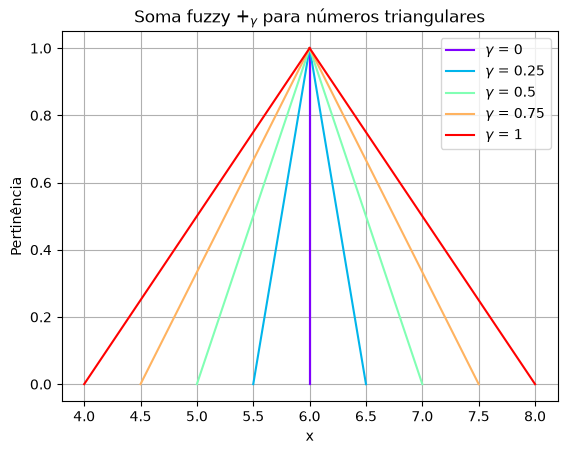

In [6]:
A = [[1,2],[3,2]]
B = [[3,4],[5,4]]

S_gammas = plota_oper_gamma(A,B, titulo = r"Soma fuzzy $+_\gamma$ para números triangulares")


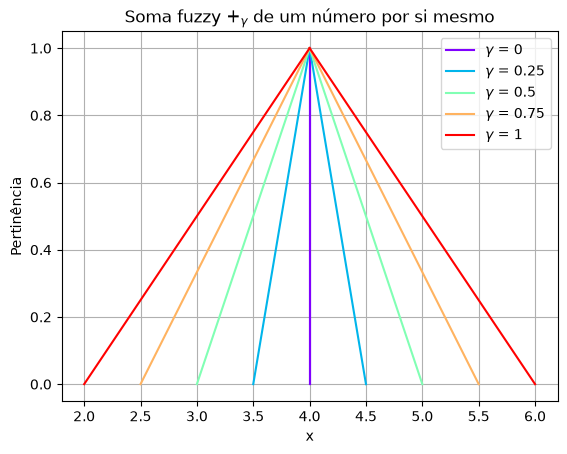

In [7]:
A = [[1,2],[3,2]]
S_gammas = plota_oper_gamma(A,A, titulo = r"Soma fuzzy $+_\gamma$ de um número por si mesmo")

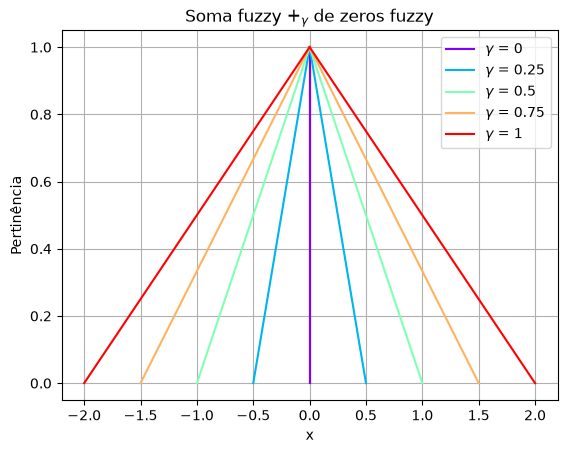

In [8]:
A = [[-1,0],[1,0]]
S_gammas = plota_oper_gamma(A,A, titulo = r"Soma fuzzy $+_\gamma$ de zeros fuzzy")
 

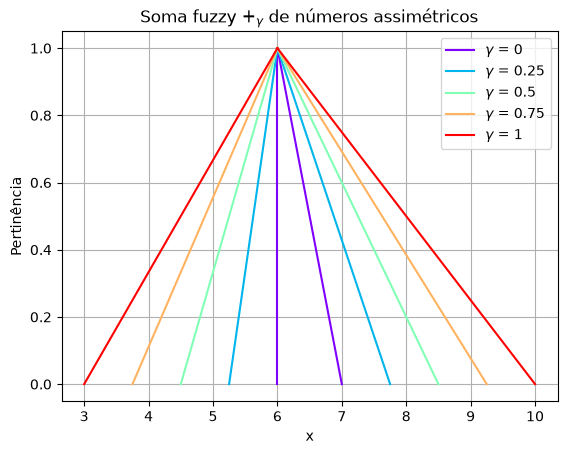

In [9]:
A = [np.linspace(1,2, 1001), np.linspace(4,2, 1001)]
B = [np.linspace(2,4, 1001), np.linspace(6,4, 1001)]

S_gammas = plota_oper_gamma(A,B, titulo = r"Soma fuzzy $+_\gamma$ de números assimétricos")
 

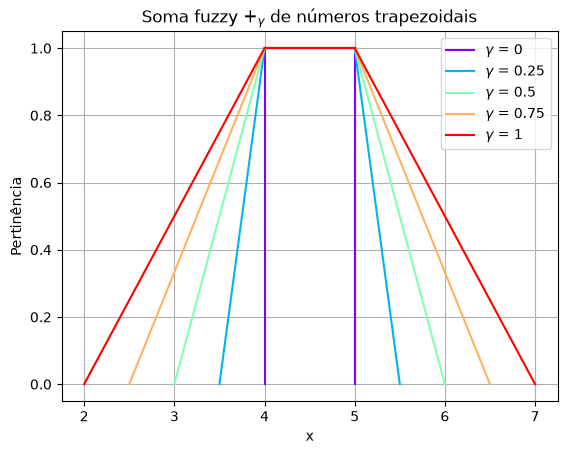

In [10]:
A = [np.linspace(1,2, 1001), np.linspace(3,2, 1001)]
B = [np.linspace(1,2, 1001), np.linspace(4,3, 1001)]

S_gammas = plota_oper_gamma(A,B, titulo = r"Soma fuzzy $+_\gamma$ de números trapezoidais")
 

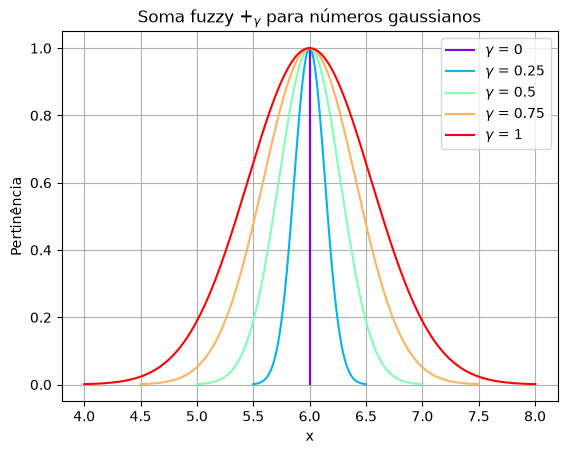

In [11]:
### EXEMPLO

def n_fuzzy_sino(u, sigma, d, int_range = 2001):

    x = np.linspace(u-d, u+d, int_range)
    alphas_ = np.exp(-((u - x)**2 / sigma))

    n_sino = np.array([x[:int_range//2+1],x[:int_range//2-1:-1]])
    alphas = alphas_[:int_range//2+1]
    
    return n_sino, alphas


A, alf = n_fuzzy_sino(2,0.15,1)
B, alf = n_fuzzy_sino(4,0.15,1)

S_gammas = plota_oper_gamma(A, B, alphas = alf, titulo = r"Soma fuzzy $+_\gamma$ para números gaussianos")

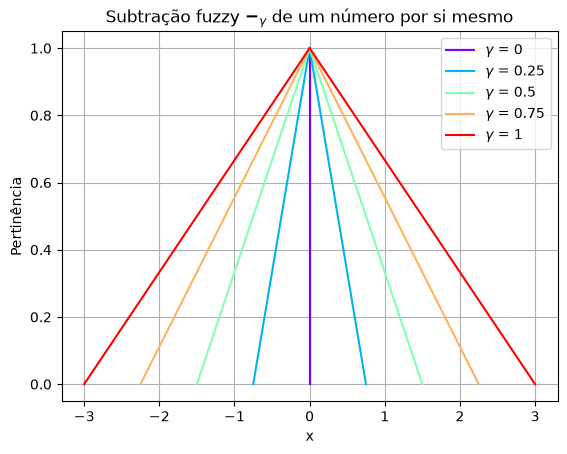

In [12]:
A = [np.linspace(1,2, 1001), np.linspace(4,2, 1001)]
A_ = [np.linspace(-4,-2, 1001), np.linspace(-1,-2, 1001)]
S_gammas = plota_oper_gamma(A,A_, titulo = r"Subtração fuzzy $-_\gamma$ de um número por si mesmo")
 

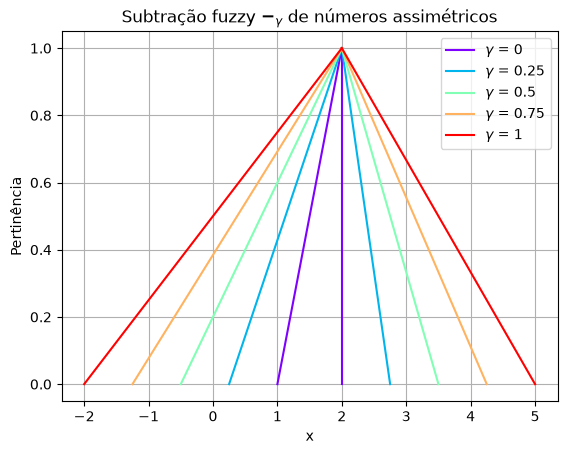

In [13]:
A = [np.linspace(-4,-2, 1001), np.linspace(-1,-2, 1001)]
B = [np.linspace(2,4, 1001), np.linspace(6,4, 1001)]

S_gammas = plota_oper_gamma(B,A, titulo = r"Subtração fuzzy $-_\gamma$ de números assimétricos")
 

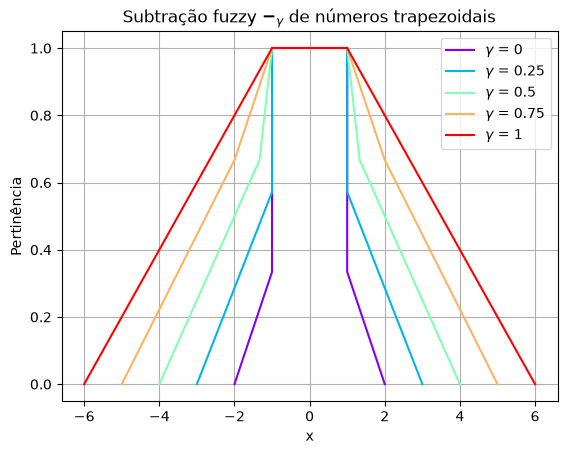

In [14]:
A = [np.linspace(2,3, 1001), np.linspace(6,5, 1001)]
B = [np.linspace(-8,-4, 1001), np.linspace(0,-4, 1001)]

S_gammas = plota_oper_gamma(A,B, titulo = r"Subtração fuzzy $-_\gamma$ de números trapezoidais")
 

## Subtração

---

In [15]:
def dif_interativa_gamma(A, B, gamma = 0):
    """
    Realiza a subtração interativa gamma de dois números fuzzy.

    Args:
        A (tuple or array-like): número fuzzy A por alfa-nível, na forma[[a1-,a2-,..., an-],[a1+,a2+,..., an+]].
        B (tuple or array-like): número fuzzy B por alfa-nível, na forma[[b1-,b2-,..., bn-],[b1+,b2+,..., bn+]].
        gamma (float): fator gamma em operações interativas por JPD.

    Returns:
        S (array-like): número fuzzy resultante da soma interativa.
        
    """
    
    a_men, a_mai = A
    b_men, b_mai = B

    a_bar = (a_men[-1] + a_mai[-1])/2
    b_bar = (b_men[-1] + b_mai[-1])/2
    c_bar = a_bar - b_bar

    at_men = np.array(a_men) - a_bar
    at_mai = np.array(a_mai) - a_bar
    bt_men = np.array(b_men) - b_bar
    bt_mai = np.array(b_mai) - b_bar

    c_men = np.zeros(len(a_men))
    c_mai = np.zeros(len(a_men))
    
    for alpha in range(len(a_men)):
        h_men = np.zeros(len(at_men))
        h_mai = np.zeros(len(at_men))
        for beta in range(alpha, len(at_men)):
            h_men[beta] = min([at_men[beta] - bt_men[beta] + gamma*(bt_men[beta] - bt_mai[beta]), 
                            at_mai[beta] - bt_mai[beta] + gamma*(at_men[beta] - at_mai[beta]), 
                            gamma*(at_men[beta] - bt_mai[beta])
                            ])
            h_mai[beta] = max([at_men[beta] - bt_men[beta] + gamma*(at_mai[beta] - at_men[beta]), 
                            at_mai[beta] - bt_mai[beta] + gamma*(bt_mai[beta] - bt_men[beta]), 
                            gamma*(at_mai[beta] - bt_men[beta])
                            ])
            
        c_men[alpha] = np.array(np.min(h_men))
        c_mai[alpha] = np.array(np.max(h_mai))

    S = [c_men - c_bar, c_mai - c_bar]
    return S

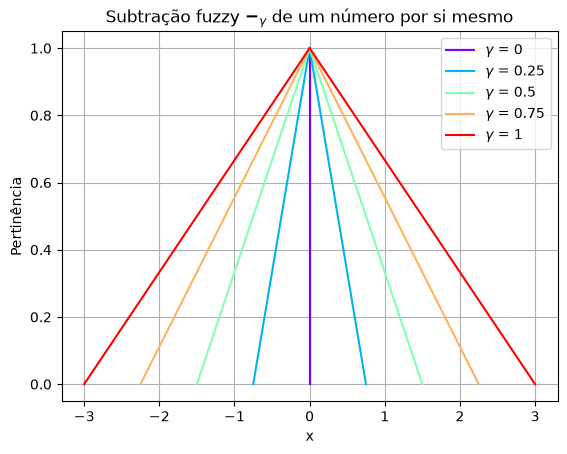

In [16]:
A = [np.linspace(1,2, 1001), np.linspace(4,2, 1001)]
S_gammas = plota_oper_gamma(A,A, oper_gamma=dif_interativa_gamma,titulo = r"Subtração fuzzy $-_\gamma$ de um número por si mesmo")

## 📚 Referências

**[1]**. L. C. Barros and R. C. Bassanezi. *Tópicos de lógica fuzzy e biomatemática*. Coleção IMECC – Textos Didáticos; volume 5, Instituto de Matemática, Estatística e Computação Científica (IMECC), Universidade Estadual de Campinas, Campinas, SP, 2006‑2010.

**[2]**. J. D. Alves. Sequências recorrentes de números fuzzy interativos: aplicações em biomatemática. Projeto de dissertação de mestrado, Universidade Estadual Paulista “Júlio de Mesquita Filho” (Unesp), Programa de Pós-Graduação em Matemática, Rio Claro-  SP, 2023.

**[3]**. V. F. Wasques. Fuzzy Differential Equations via Interactive Arithmetic: Applications in Biomathematics.
PhD thesis, lnstitute of Mathematics, Statistics and Scientific Computing, Campinas, São Paulo, 2019.

https://proceedings.sbmac.org.br/sbmac/article/view/4171/4224